In [3]:
from pathlib import Path
import vtk
from pathlib import Path
from scipy.stats import multivariate_normal
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from scipy import io as scio
from scipy import stats as sci_stats
import pickle
import scipy.spatial as sp
from typing import Union,Dict,List
import copy
import sys
sys.path.append('../scripts')
import gpa

In [4]:
path_to_processed_cohort = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_skull_workdir"
result_energies = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/malefemale_pvals.mat"

In [5]:
def compute_center_of_mesh(mesh):
    centerOfMassFilter = vtk.vtkCenterOfMass()
    centerOfMassFilter.SetInputData(mesh)
    centerOfMassFilter.SetUseScalarsAsWeights(False)
    centerOfMassFilter.Update();
    center = centerOfMassFilter.GetCenter()
    return center



reader = vtk.vtkOBJReader()
num_of_points = 0
meshes_dict = {}
for path in tqdm(list(Path(path_to_processed_cohort).iterdir())):
    mesh_file = path / "head_affine_registered.obj"
    if not mesh_file.exists():
        continue
    reader.SetFileName(mesh_file)
    reader.Update()
    mesh = reader.GetOutput()
    points = mesh.GetPoints()
    center_of_mesh = np.array( compute_center_of_mesh(mesh) )
    num_of_points = points.GetNumberOfPoints()
    res_mesh = []
    for i in range(points.GetNumberOfPoints()):
        pt = points.GetPoint(i)
        res_mesh.append(list( np.array( pt) - center_of_mesh ))
    meshes_dict[str( mesh_file.parent.name ) ] = res_mesh

  0%|          | 0/767 [00:00<?, ?it/s]

In [ ]:
def write_obj_2_file(obj,filename):
    f = open(filename,"wb")
    pickle.dump(obj,f)
    f.close()

def compute_descriptive_statistics(points):
    mean = np.mean(points, axis=0)
    std_dev = np.std(points, axis=0)
    # Add any other statistics you're interested in
    return mean, std_dev

def compute_outliers(meshes_dict: Union[Dict[str,np.ndarray],List[np.ndarray]]):
    
    stats = []
    index_sum=None
    if isinstance(meshes_dict,list):
        num_of_points = len( meshes_dict[0] )
        working_dict = list(zip(range(num_of_points),meshes_dict))
        
    else:
        num_of_points = len( list(meshes_dict.values())[0] )
        working_dict = list(meshes_dict.items())
            
    for i in tqdm(range(num_of_points)): # i in range of num_of_points
        index = []
        points = []
        #print (i, working_dict)
        for key, mesh_v in working_dict:
            index.append(key)
            points.append(mesh_v[i])
        
        df = pd.DataFrame( data = points, index=index, columns=['x','y','z'])
        
        indexes = (np.abs(sci_stats.zscore(df)) < 2).all(axis=1)
        
        if index_sum is None:
            index_sum = (~indexes).astype(int)
        else:
            index_sum += (~indexes).astype(int)
        df = df[indexes]
        stats.append(df.describe())
    
    return stats, index_sum

    

stats, index_sum = compute_outliers(meshes_dict)



In [6]:


meshes_dict_copy = copy.copy(meshes_dict)


#copy dict 
# for k,v in sorted(index_sum.items(), key=lambda x:x[1]):
#     if v > 1000:
#         meshes_dict_copy.pop(k)

In [7]:
#procrustes analysis

ref_mesh, aligned_meshes, shapes= gpa.gpa(meshes_dict_copy,max_iterations=100, threshold=1e-11)

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/766 [00:00<?, ?it/s]

Procrustes distance  492.0238229604362


  0%|          | 0/766 [00:00<?, ?it/s]

Procrustes distance  0.0008363740108543692


  0%|          | 0/766 [00:00<?, ?it/s]

Procrustes distance  1.4217060385822027e-09


  0%|          | 0/766 [00:00<?, ?it/s]

Procrustes distance  2.416679557012534e-15


  0%|          | 0/767 [00:00<?, ?it/s]

In [11]:
#divide male to female
males = { k: v for k,v in shapes.items() if k.split("_")[1] == "M" }
females = { k: v for k,v in shapes.items() if k.split("_")[1] == "F" }

In [ ]:
list(males.values())

In [ ]:
# mann w
p_values = []

for i in tqdm(range(num_of_points)):
    pt_m = []
    pt_f = [] 
    for _,v in males.items():
        pt_m.append( v[i,:])
    for _,v in females.items():
        pt_f.append( v[i,:])
    
    pt_m = np.stack(pt_m)
    pt_f = np.stack(pt_f)
    ks_p_values = []
    for dim in range(3):
        #ks_statistic, ks_p_value = sci_stats.ttest_ind(pt_m[:, dim], pt_f[:, dim])
        ks_statistic, ks_p_value = sci_stats.ks_2samp(pt_m[:, dim], pt_f[:, dim])
        ks_p_values.append(ks_p_value)
    
    p_values.append(ks_p_values)
    
p_values =np.stack(p_values)    
    

In [ ]:
#mean mesh
#iterate over faces 

res_array = (p_values > 0.005).any(axis=1)
polygons = mesh.GetPolys()
faces = []
# Iterate over the polygons to extract the faces
polygons.InitTraversal()
while True:
    faceIds = vtk.vtkIdList()
    if polygons.GetNextCell(faceIds):
        face = [faceIds.GetId(i) for i in range(faceIds.GetNumberOfIds())]
        faces.append(face)
    else:
        break
        
### compute colors and write to mat 
energies = []
for x in faces:
    en = 0 
    for p in x:
        en+= res_array[p]
    energies.append(en > 2)

scio.savemat(result_energies, {"energies": energies})


In [ ]:
sci_stats.describe(pt_m)

In [ ]:
sci_stats.mannwhitneyu(pt_m,pt_f,alternative='two-sided')

In [ ]:
(p_values > 0.05).any(axis=1)

In [ ]:
sci_stats.ttest_ind(pt_f,pt_m)

In [ ]:
sci_stats.describe(pt_f)

In [ ]:
face

In [ ]:
import gpa

In [ ]:
from importlib import reload
reload(gpa)

In [13]:
errors_males = []
for _,sub in males.items():
    errors_males.append( gpa.procreustes_alignment(ref_mesh,sub)[1] )
    
errors_females = []
for _,sub in females.items():
    errors_females.append( gpa.procreustes_alignment(ref_mesh,sub)[1] )

array([[<AxesSubplot:title={'center':'0'}>]], dtype=object)

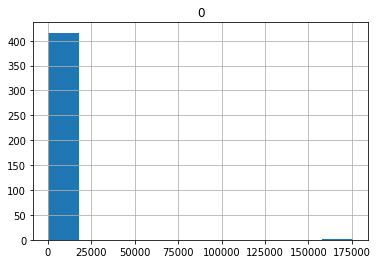

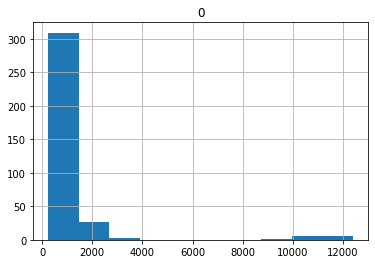

In [14]:
dfm = pd.DataFrame(errors_males,index=males.keys())
dfm.hist()
dff = pd.DataFrame(errors_females,index=females.keys())
dff.hist()

In [ ]:
dff[dff<4000].hist()

In [16]:
np.percentile(dfm.values,95),np.percentile(dff.values,95)

(2319.787416774281, 2533.545380528445)

In [ ]:
dfm[dfm>np.percentile(dfm.values,95)].dropna()

In [ ]:
### remove outliers:
import os
keys = list((dff[dff>np.percentile(dff.values,99)].dropna()).index)


def remove(fn):
    try:
        os.remove(fn)
    except:
        pass

for k in tqdm(keys):
    
        folder = Path(path_to_processed_cohort) / k

        try:
            
            remove( folder / "affine_head.mat", )
            remove( folder / "coregistered_head.nii.gz" )
            remove( folder / "oriented_image.nii.gz" )
            remove( folder / "oriented_mask.nii.gz" )
            remove( folder / "bone_coregistration_mask.nii.gz" )
            remove( folder / "head_affine_registered.obj" )
            remove( folder / "nonlin_image.nii.gz" )
            remove( folder / "nl_transformation_params.txt" )
        except Exception as e:
            print(e)
            pass
        


SAVE MALE_FEMALE COHORT

In [9]:
males = { k: v for k,v in meshes_dict_copy.items() if k.split("_")[1] == "M" }
females = { k: v for k,v in meshes_dict_copy.items() if k.split("_")[1] == "F" }
o_f =   "/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/wt_cohorts_pts.pkl"
of = open(o_f,'wb')
pickle.dump({"M": males, "F": females},of)
of.close()